# 08 · Phase 4: Failure Mode & Clinical Error Audit

**Goal (sprint plan, Phase 4):** understand *where* and *why* the Phase 2 classifier fails (EfficientNet-B0, `nb06crops_weighted`, high-sensitivity threshold).

- **p4-t1:** categorise false positives (FP) and false negatives (FN) by view, brightness/contrast and acoustic shadowing.
- **p4-t2:** check how segmentation failures and conflicting labels (e.g. images 4 & 296) propagate into classification.
- **p4-t3:** success vs. failure case figure.

The parts that need Grad-CAM (`xai_metrics.csv` from Phase 3) are in **section 9**, which runs automatically once that file exists.

All metrics are **out-of-fold**: each image is predicted by the fold model that did not see it during training.

### Setup
Imports, project paths and the output folder `results/phase4_error_audit/`, where every table and figure of this notebook is saved so it can be reused in the final report.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
P2   = ROOT / 'results/phase2_classifier'
OUT  = ROOT / 'results/phase4_error_audit'
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 160)
rng = np.random.default_rng(0)

## 1. Data

- `oof_predictions.csv` (Phase 2): probability, fold threshold and TP/TN/FP/FN outcome.
- `crop_audit.csv` (Phase 2): view, Dice of the DeepLabV3+ kidney prediction and kidney coverage of the crop.
- `bbdd_kidney/labels/*.txt`: global pathologies and lesion boxes with their class (1–9).

### Load and merge everything into one table (`df`)
We read the Phase 2 out-of-fold predictions, the crop audit (view, crop quality) and parse the original annotation files to get, for every image: global pathologies, number of lesions, lesion classes and the area of the smallest lesion. Everything is merged on `image_id`, giving one row per image (1,985 rows).

We also define:
- `error`: True if the prediction is a FP or FN;
- `margin` = probability − threshold: how far the prediction is from the decision boundary (negative = predicted healthy). Large |margin| on an error means the model was *confidently wrong*.

In [2]:
pred  = pd.read_csv(P2 / 'nb06crops_weighted/imagenet/oof_predictions.csv')
audit = pd.read_csv(P2 / 'crop_audit.csv')[['image_id','view','dice','box_iou','kidney_coverage','crop_x0','crop_y0','crop_x1','crop_y1']]
lcov  = pd.read_csv(P2 / 'lesion_crop_coverage.csv')

def parse_label(p):
    g, boxes = (0, 0), []
    for line in p.read_text().splitlines():
        if line.startswith('Global pathologies'):
            g = tuple(int(x) for x in line.split(':')[1].split())
        elif line.startswith('Bounding box'):
            v = [int(x) for x in line.split(':')[1].split()]
            boxes.append(v)          # x, y, w, h, class
    return g, boxes

rows = []
for p in (ROOT / 'bbdd_kidney/labels').glob('*.txt'):
    g, boxes = parse_label(p)
    rows.append(dict(image_id=int(p.stem), global_1=g[0], global_2=g[1],
                     n_lesions=len(boxes),
                     lesion_classes=sorted({b[4] for b in boxes}),
                     min_lesion_area=min((b[2]*b[3] for b in boxes), default=np.nan)))
lab = pd.DataFrame(rows)

df = pred.merge(audit, on='image_id').merge(lab, on='image_id')
df['error'] = df.outcome.isin(['FP','FN'])
df['margin'] = df.probability - df.threshold           # <0 → predicted healthy
print(df.shape); df.outcome.value_counts()

(1985, 28)


outcome
TP    1373
TN     237
FP     213
FN     162
Name: count, dtype: int64

**Result.** 1,985 images: 1,373 TP, 237 TN, **213 FP** and **162 FN**, i.e. 375 errors to explain. These are the numbers reported in the Phase 2 handoff, so the merge is consistent.

**Class names.** The URI-CADS paper (`Documents/s10278-024-01055-4.pdf`, Table 1) lists 2 global pathologies (PCD, HC) and 9 local ones (simple cyst, complicated cyst, pyramids, hydronephrosis, lithiasis, angiomyolipoma, solid renal mass, cortex thinning, cortex eschar). **The numeric order 1–9 used in the `.txt` files is not confirmed**, so the class numbers are used here. Fill in `CLASS_NAMES` once the official mapping is known.

In [3]:
CLASS_NAMES = {k: f'class {k}' for k in range(1, 10)}   # TODO: fill in with the official mapping
GLOBAL_NAMES = {'global_1': 'global 1 (PCD?)', 'global_2': 'global 2 (HC?)'}

## 2. Overall summary

### Overall performance
`rates()` is a helper used throughout the notebook: for any subset of images it counts TP/TN/FP/FN and computes **sensitivity** (share of pathological kidneys detected), **specificity** (share of healthy kidneys correctly called healthy) and the error rate.

In [4]:
def rates(d):
    tp, tn, fp, fn = [(d.outcome == k).sum() for k in ['TP','TN','FP','FN']]
    return pd.Series(dict(n=len(d), TP=tp, TN=tn, FP=fp, FN=fn,
        sensitivity=tp/(tp+fn) if tp+fn else np.nan,
        specificity=tn/(tn+fp) if tn+fp else np.nan,
        error_rate=(fp+fn)/len(d)))
rates(df).to_frame('overall').T.round(3)

,n,TP,TN,FP,FN,sensitivity,specificity,error_rate
overall,1985.0,1373.0,237.0,213.0,162.0,0.894,0.527,0.189


**Interpretation.** Sensitivity is high (**0.894**) but specificity is low (**0.527**). This is expected: the team chose a threshold that guarantees ≈90% sensitivity on validation, because missing a sick kidney is worse than an unnecessary referral. The price is that almost half of the healthy kidneys are flagged. Note the class imbalance: only 450 of 1,985 images are healthy.

## 3. Errors by view (p4-t1)

There are two views: `view 0` (1,842 images) and `view 1` (143). According to the paper (p. 5), 93% of images are transversal and 7% longitudinal, which would make `view 1` the longitudinal one. Note that the sprint plan and the segmentation notebook call the difficult minority view "transverse". The naming should be confirmed with the team.

We compute the same metrics separately for each view.

In [5]:
by_view = df.groupby('view').apply(rates, include_groups=False).round(3)
by_view.to_csv(OUT / 'errors_by_view.csv'); by_view

,n,TP,TN,FP,FN,sensitivity,specificity,error_rate
view,,,,,,,,
0,1842.0,1293.0,203.0,193.0,153.0,0.894,0.513,0.188
1,143.0,80.0,34.0,20.0,9.0,0.899,0.630,0.203


**Interpretation.** Sensitivity is practically the same in both views (0.894 vs 0.899), and specificity is actually *higher* in view 1 (0.63 vs 0.51). So, although the minority view was harder for **segmentation**, it does **not** make the **classifier** worse. With only 143 images (54 healthy) in view 1, the specificity difference is not reliable.

## 4. Errors by crop quality (p4-t2: do segmentation failures propagate?)

### Does a bad crop cause classification errors?
The classifier only sees the crop produced by the Phase 1 segmentation model. If the segmentation is poor (low Dice with the doctor's kidney mask), the crop may miss part of the kidney, so we would expect more errors. We group images by crop Dice.

In [6]:
df['dice_bin'] = pd.cut(df.dice, [-0.01, 0.80, 0.90, 0.95, 1.0], labels=['<0.80','0.80–0.90','0.90–0.95','≥0.95'])
by_dice = df.groupby('dice_bin', observed=True).apply(rates, include_groups=False).round(3)
by_dice.to_csv(OUT / 'errors_by_crop_dice.csv'); by_dice

,n,TP,TN,FP,FN,sensitivity,specificity,error_rate
dice_bin,,,,,,,,
<0.80,89.0,76.0,4.0,3.0,6.0,0.927,0.571,0.101
0.80–0.90,329.0,257.0,25.0,28.0,19.0,0.931,0.472,0.143
0.90–0.95,712.0,513.0,75.0,74.0,50.0,0.911,0.503,0.174
≥0.95,855.0,527.0,133.0,108.0,87.0,0.858,0.552,0.228


**Interpretation.** The opposite of what we expected: the error rate is **lowest** for the worst crops (10% for Dice < 0.80) and **highest** for the best crops (23% for Dice ≥ 0.95). Poor crops are usually loose crops that still contain the kidney (the crop is padded), and many of them are clearly pathological kidneys with a distorted shape, which are easy to classify. **Conclusion: segmentation quality is not what drives classification errors.**

The 10 images with the worst segmentation, to check what happened to them in classification.

In [7]:
worst_seg = df.nsmallest(10, 'dice')[['image_id','view','dice','kidney_coverage','true_label','probability','threshold','outcome']]
worst_seg.to_csv(OUT / 'worst_segmentation_cases.csv', index=False); worst_seg

,image_id,view,dice,kidney_coverage,true_label,probability,threshold,outcome
92,1081,0,0.000000,0.000000,1,0.396667,0.273857,TP
1231,32,1,0.386230,1.000000,0,0.988581,0.273857,FP
669,1600,1,0.391753,1.000000,1,0.991284,0.273857,TP
1970,986,0,0.393767,0.429875,1,0.715034,0.273857,TP
1969,985,0,0.423772,0.588285,1,0.537017,0.273857,TP
217,1194,0,0.477267,1.000000,1,0.758953,0.224536,TP
1032,1928,0,0.508334,1.000000,1,0.997477,0.504688,TP
1546,603,1,0.555808,1.000000,1,0.926507,0.224536,TP
858,1771,1,0.584137,1.000000,1,0.435690,0.224536,TP
602,1540,0,0.609119,0.702258,1,0.160313,0.273857,FN


**Interpretation.** Even with very poor crops, 8 of the 10 worst-segmented images are still classified correctly. Image **1081** is the extreme case: the segmentation missed the kidney completely (Dice 0, the crop is a small patch of background), yet the prediction is still pathological (p = 0.40 > threshold 0.27), almost certainly by chance. Only image 1540 becomes a FN and image 32 a FP.

## 5. Errors by lesion type (pathological images only)

An image with several lesion classes counts once in each. The relevant metric here is **sensitivity**, i.e. which lesions the model misses (FN).

### Which lesions does the model miss?
For pathological images only, we compute sensitivity per lesion class (an image with several lesion classes counts in each), and for the two global pathologies.

In [8]:
path = df[df.true_label == 1].explode('lesion_classes')
path['lesion'] = path.lesion_classes.map(CLASS_NAMES).fillna('no box (global only)')
by_lesion = path.groupby('lesion').apply(rates, include_groups=False)[['n','TP','FN','sensitivity']].sort_values('sensitivity').round(3)

glob = []
for col, name in GLOBAL_NAMES.items():
    d = df[(df.true_label == 1) & (df[col] == 1)]
    glob.append(rates(d).rename(name))
by_global = pd.DataFrame(glob)[['n','TP','FN','sensitivity']].round(3)
by_lesion.to_csv(OUT / 'sensitivity_by_lesion_class.csv'); by_global.to_csv(OUT / 'sensitivity_by_global_pathology.csv')
display(by_lesion); display(by_global)

,n,TP,FN,sensitivity
lesion,,,,
class 6,11.0,7.0,4.0,0.636
class 5,33.0,22.0,11.0,0.667
class 9,38.0,32.0,6.0,0.842
no box (global only),212.0,182.0,30.0,0.858
class 8,102.0,90.0,12.0,0.882
class 2,595.0,535.0,60.0,0.899
class 4,161.0,148.0,13.0,0.919
class 7,469.0,437.0,32.0,0.932
class 1,87.0,82.0,5.0,0.943


,n,TP,FN,sensitivity
global 1 (PCD?),595.0,553.0,42.0,0.929
global 2 (HC?),509.0,471.0,38.0,0.925


**Interpretation.** Sensitivity is 0.84–0.98 for the other classes but drops clearly for **rare classes**: class 6 (**0.64**, 11 images) and class 5 (**0.67**, 33 images). The model has seen too few examples of them. Images with only a global pathology and no lesion box are also slightly harder (0.86). The global pathologies themselves are well detected (≈0.93). *Caveat:* rare classes have few images, so these estimates are uncertain.

We split pathological images into quartiles of lesion size (area of the smallest box), and check images where a lesion was partly cut off by the automatic crop.

In [9]:
# Are small lesions, or lesions cut off by the crop, missed more often?
p = df[(df.true_label == 1) & df.n_lesions.gt(0)].copy()
p['lesion_size'] = pd.qcut(p.min_lesion_area, 4, labels=['Q1 (smallest)','Q2','Q3','Q4 (largest)'])
cut = lcov[lcov.lesion_coverage < 1].image_id.unique()
p['lesion_cut_off'] = p.image_id.isin(cut)
display(p.groupby('lesion_size', observed=True).apply(rates, include_groups=False)[['n','FN','sensitivity']].round(3))
display(p.groupby('lesion_cut_off').apply(rates, include_groups=False)[['n','FN','sensitivity']].round(3))

,n,FN,sensitivity
lesion_size,,,
Q1 (smallest),332.0,44.0,0.867
Q2,332.0,38.0,0.886
Q3,328.0,29.0,0.912
Q4 (largest),331.0,21.0,0.937


,n,FN,sensitivity
lesion_cut_off,,,
False,1284.0,125.0,0.903
True,39.0,7.0,0.821


**Interpretation.** Smaller lesions are missed more: sensitivity goes from **0.87** for the smallest quartile to **0.94** for the largest. Lesions cut off by the crop are also missed more often (0.82 vs 0.90), but this only affects 39 images, so it has little impact overall.

## 6. Brightness, contrast and acoustic shadowing (p4-t1)

Computed on the **crop the model actually sees** (`oof_kidney_crops/`):
- **brightness:** mean intensity (0–255);
- **contrast:** standard deviation of intensity;
- **shadow (proxy):** fraction of very dark pixels (< 20) in the lower half of the crop. This is only an automatic indicator; real shadowing should be confirmed visually (section 8).

In [10]:
def img_stats(iid):
    a = np.asarray(Image.open(ROOT / f'oof_kidney_crops/{iid}.jpg').convert('L'), dtype=np.float32)
    h = a.shape[0]
    return dict(image_id=iid, brightness=a.mean(), contrast=a.std(),
                shadow=(a[h//2:] < 20).mean())
stats = pd.DataFrame([img_stats(i) for i in df.image_id])
df = df.merge(stats, on='image_id')
summ = df.groupby('outcome')[['brightness','contrast','shadow']].median().round(3)
summ.to_csv(OUT / 'intensity_by_outcome.csv'); summ

,brightness,contrast,shadow
outcome,,,
FN,59.342999,35.326000,0.039
FP,57.958000,37.361000,0.031
TN,59.759998,35.091999,0.048
TP,62.842999,41.881001,0.043


**Interpretation.** The median values are very similar across outcomes. The clearest difference is **contrast**: TPs have higher contrast (≈42) than FNs (≈35). The shadow proxy shows no meaningful difference.

Box plots of the three measures for each outcome (outliers hidden for readability).

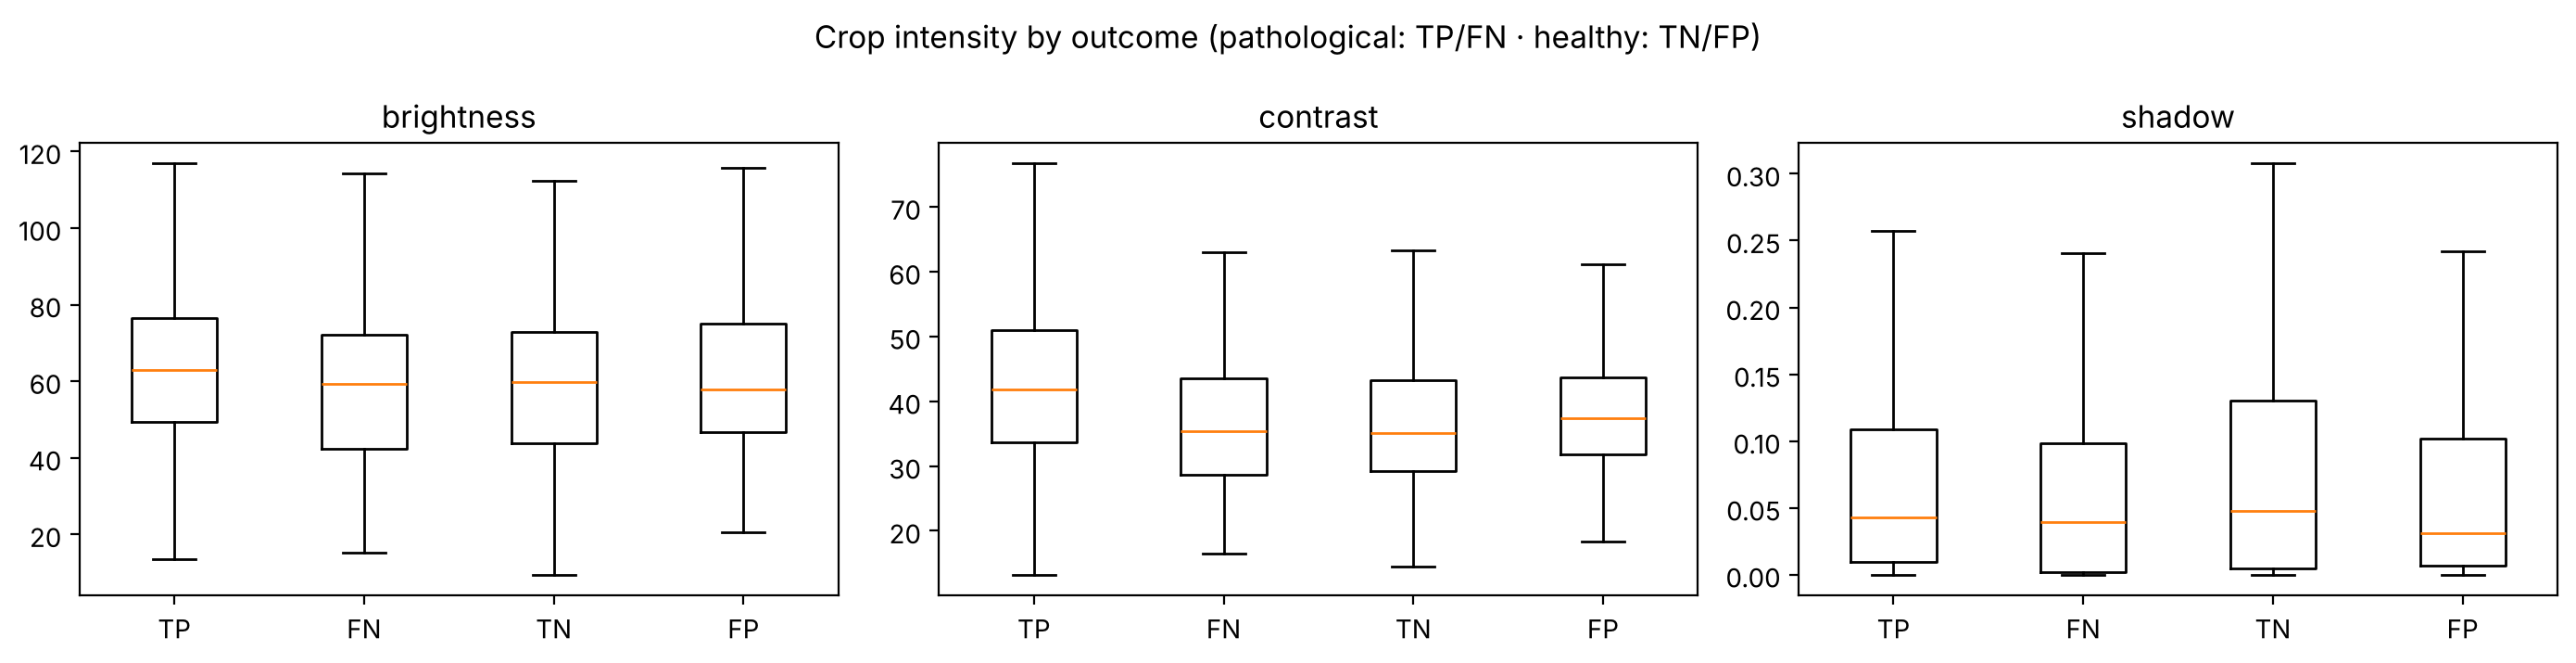

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
order = ['TP','FN','TN','FP']
for ax, col in zip(axs, ['brightness','contrast','shadow']):
    ax.boxplot([df.loc[df.outcome == o, col] for o in order], tick_labels=order, showfliers=False)
    ax.set_title(col)
fig.suptitle('Crop intensity by outcome (pathological: TP/FN · healthy: TN/FP)')
fig.tight_layout(); fig.savefig(OUT / 'intensity_by_outcome.png', dpi=150); plt.show()

**How to read it.** Compare TP vs FN (pathological images) and TN vs FP (healthy images). The only visible shift is FN having lower contrast than TP.

To quantify this, we split images into three equal groups (terciles: low / medium / high) of each measure and compute the miss rate (FN rate among pathological images) and false-alarm rate (FP rate among healthy images).

In [12]:
# Error rate by tercile of each variable, separately for healthy and pathological images
res = []
for col in ['brightness','contrast','shadow']:
    for lbl, name, err in [(1,'pathological','FN'),(0,'healthy','FP')]:
        d = df[df.true_label == lbl].copy()
        d['tercile'] = pd.qcut(d[col].rank(method='first'), 3, labels=['low','medium','high'])
        r = d.groupby('tercile', observed=True).outcome.apply(lambda s: (s == err).mean())
        res.append(pd.Series(r.values, index=r.index, name=f'{col} · {name} ({err})'))
terc = pd.DataFrame(res).round(3)
terc.to_csv(OUT / 'error_rate_by_intensity_tercile.csv'); terc

tercile,low,medium,high
brightness · pathological (FN),0.131,0.094,0.092
brightness · healthy (FP),0.413,0.527,0.480
contrast · pathological (FN),0.160,0.100,0.057
contrast · healthy (FP),0.387,0.507,0.527
shadow · pathological (FN),0.129,0.076,0.111
shadow · healthy (FP),0.480,0.527,0.413


**Interpretation.** **Low contrast is the strongest image-quality factor**: in the lowest-contrast tercile, **16%** of pathological kidneys are missed vs **6%** in the highest. Darker images also lead to slightly more FN (13% vs 9%). For healthy images, FP rates are high everywhere (39–53%) without a clear pattern, so FPs are not explained by brightness, contrast or shadowing.

## 7. Conflicting labels (p4-t2)

`results/eda/duplicate_pairs.csv` lists near-identical image pairs (identical images or consecutive frames of the same exam). Here we keep the pairs where **one image is labelled healthy and the other pathological**, such as 4 and 296. No model can get both right, so some "errors" are actually label noise.

We keep only pairs judged as *identical image* or *same exam (consecutive frame)* and with a different diagnosis, and add the model's probability and outcome for each image.

In [13]:
dup = pd.read_csv(ROOT / 'results/eda/duplicate_pairs.csv')
dup = dup[dup.verdict.isin(['identical image','same exam (consecutive frame)'])]
conf = dup[dup.diag_a != dup.diag_b][['img_a','img_b','verdict','diag_a','diag_b']]
o = df.set_index('image_id')
for s in 'ab':
    conf[f'prob_{s}']    = conf[f'img_{s}'].map(o.probability).round(3)
    conf[f'outcome_{s}'] = conf[f'img_{s}'].map(o.outcome)
conf.to_csv(OUT / 'conflicting_label_pairs.csv', index=False)
print(len(conf), 'conflicting pairs'); conf

2 conflicting pairs


,img_a,img_b,verdict,diag_a,diag_b,prob_a,outcome_a,prob_b,outcome_b
21,4,296,identical image,1,0,0.988,TP,0.989,FP
93,296,297,same exam (consecutive frame),0,1,0.989,FP,0.990,TP


**Interpretation.** Two conflicting pairs, both involving image **296**: it is labelled healthy but is identical to image 4 and a consecutive frame of image 297, both labelled pathological. The model gives all three ≈0.99. So the FP on 296 is most likely a **labelling error**, not a model error, and should be reported to the clinicians.

In [14]:
conflict_ids = set(conf.img_a) | set(conf.img_b)
print('Errors on images with conflicting labels:',
      df[df.image_id.isin(conflict_ids) & df.error].shape[0], 'of', df.error.sum())

Errors on images with conflicting labels: 1 of 375


Only 1 of the 375 errors comes from conflicting labels, so label noise of this kind is rare and does not change the overall results.

## 8. Success vs. failure cases (p4-t3, version without Grad-CAM)

We pick 2 examples of each case type and show, for each, the **full image** (cyan box = automatic crop, red boxes = lesions annotated by the doctors) and the **crop the classifier sees**. The title shows the outcome, the predicted probability and the fold threshold (green = correct, red = error). The figure is saved as `success_vs_failure_grid.png` for the report.

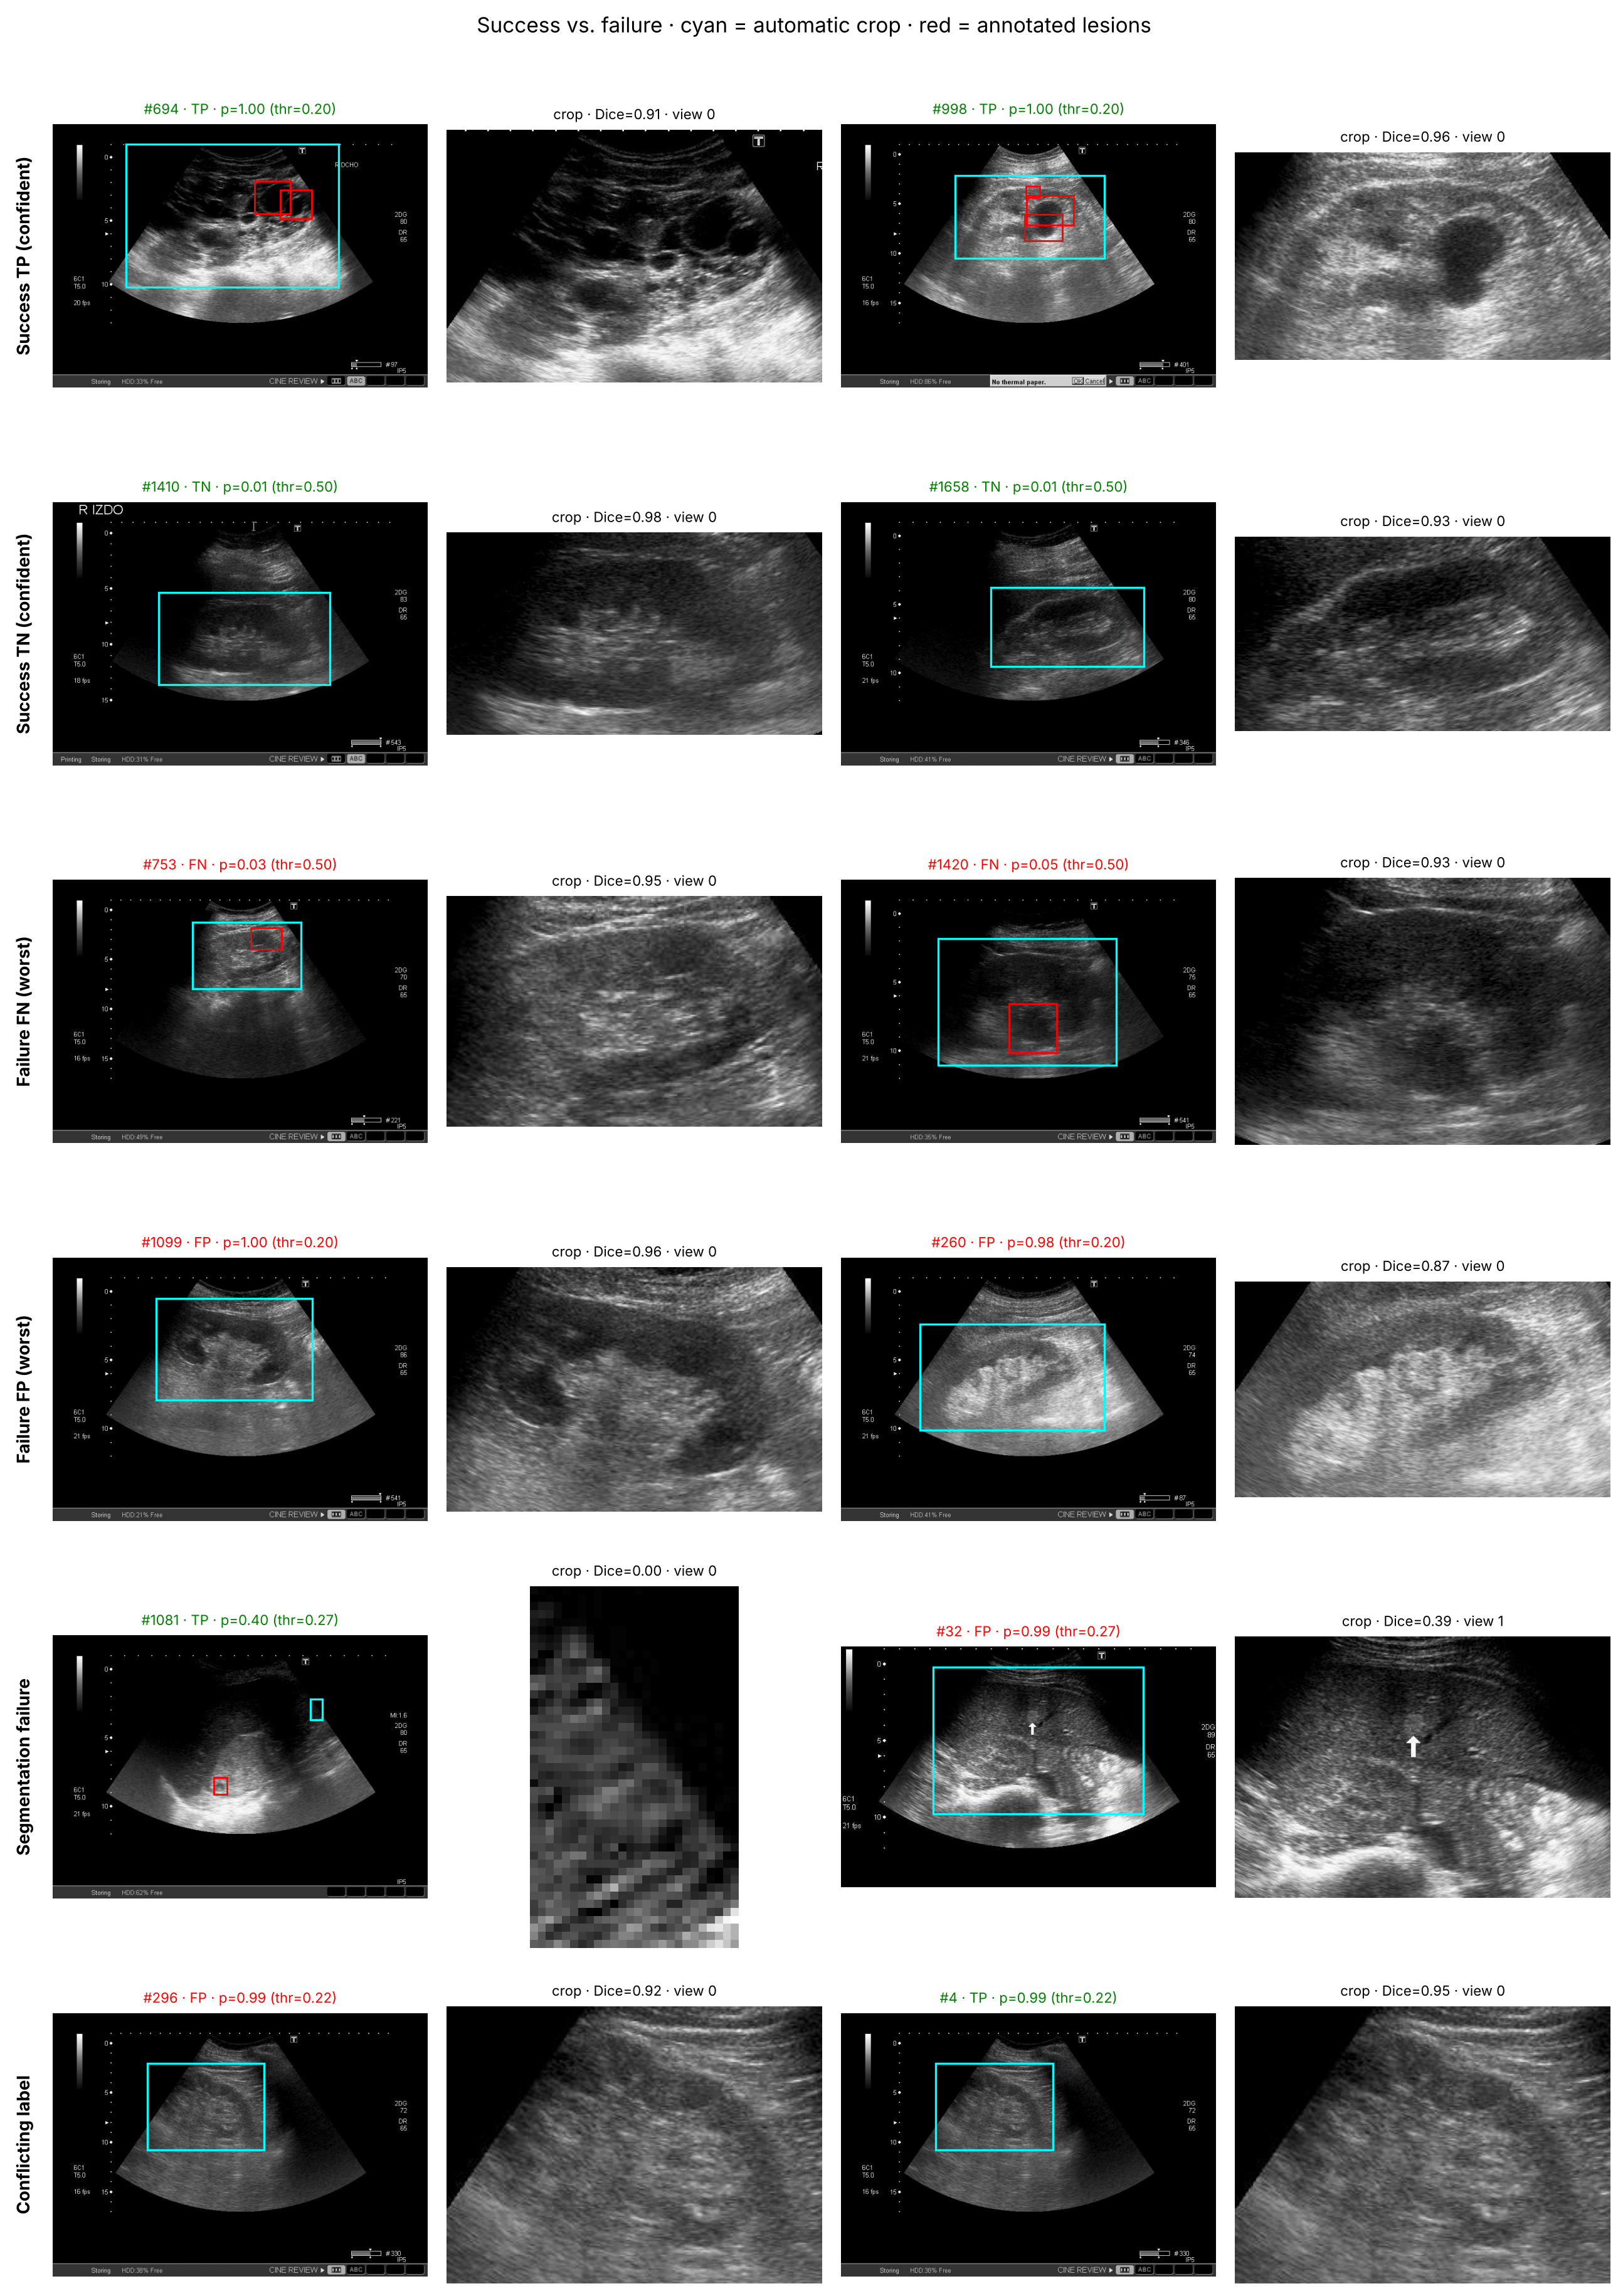

In [15]:
def show_case(ax_full, ax_crop, r):
    im = Image.open(ROOT / f'bbdd_kidney/images/{r.filename}').convert('L')
    ax_full.imshow(im, cmap='gray')
    x0, y0, x1, y1 = r.crop_x0, r.crop_y0, r.crop_x1, r.crop_y1
    ax_full.add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0, fill=False, ec='cyan', lw=1.2))
    _, boxes = parse_label(ROOT / f'bbdd_kidney/labels/{r.image_id}.txt')
    for x, y, w, h, c in boxes:
        ax_full.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec='red', lw=1))
    ax_crop.imshow(Image.open(ROOT / f'oof_kidney_crops/{r.image_id}.jpg'), cmap='gray')
    col = 'green' if r.outcome in ('TP','TN') else 'red'
    ax_full.set_title(f'#{r.image_id} · {r.outcome} · p={r.probability:.2f} (thr={r.threshold:.2f})', fontsize=8, color=col)
    ax_crop.set_title(f'crop · Dice={r.dice:.2f} · view {r.view}', fontsize=8)
    for a in (ax_full, ax_crop): a.axis('off')

picks = {
    'Success TP (confident)': df[df.outcome == 'TP'].nlargest(2, 'margin'),
    'Success TN (confident)': df[df.outcome == 'TN'].nsmallest(2, 'margin'),
    'Failure FN (worst)':     df[df.outcome == 'FN'].nsmallest(2, 'margin'),
    'Failure FP (worst)':     df[df.outcome == 'FP'].nlargest(2, 'margin'),
    'Segmentation failure':   df.nsmallest(2, 'dice'),
    'Conflicting label':      df[df.image_id.isin([4, 296])],
}
fig, axs = plt.subplots(len(picks), 4, figsize=(13, 3.1*len(picks)))
for i, (name, d) in enumerate(picks.items()):
    for j, (_, r) in enumerate(d.head(2).iterrows()):
        show_case(axs[i, 2*j], axs[i, 2*j+1], r)
    axs[i, 0].text(-0.05, 0.5, name, transform=axs[i, 0].transAxes, rotation=90, va='center', ha='right', fontsize=10, weight='bold')
fig.suptitle('Success vs. failure · cyan = automatic crop · red = annotated lesions', y=1.0)
fig.tight_layout(); fig.savefig(OUT / 'success_vs_failure_grid.png', dpi=150, bbox_inches='tight'); plt.show()

**What the figure shows.**
- **Successes:** correct, confident predictions on well-cropped kidneys; the TP examples have clearly visible dark lesions inside the crop.
- **Worst FN:** the kidney is well cropped (Dice ≈ 0.94) but the lesions are subtle and low-contrast, and the model is confidently wrong (p ≤ 0.05).
- **Worst FP:** healthy kidneys with visible internal structures (sinus, pyramids) that the model probably confuses with lesions; Grad-CAM (Phase 3) is needed to confirm.
- **Segmentation failure:** image 1081 (crop missed the kidney) and image 32 (view 1, the crop includes a lot of surrounding tissue).
- **Conflicting label:** images 296 and 4 are the same image with opposite labels.

## 9. Merge with Grad-CAM (Phase 3), pending `xai_metrics.csv`

Once `xai_metrics.csv` is available, this cell merges it on `image_id` and compares Grad-CAM metrics (anatomical containment, pointing game, lesion IoU) between correct and incorrect predictions. Adjust `XAI_COLS` if the column names differ.

In [16]:
cands = list(ROOT.glob('results/**/xai_metrics.csv'))
if cands:
    xai = pd.read_csv(cands[0])
    XAI_COLS = [c for c in xai.columns if c not in ('image_id','filename','fold')]
    dx = df.merge(xai.drop(columns=[c for c in ('filename','fold') if c in xai]), on='image_id', how='left')
    t = dx.groupby('outcome')[XAI_COLS].mean(numeric_only=True).round(3)
    t.to_csv(OUT / 'xai_by_outcome.csv'); display(t)
else:
    print('xai_metrics.csv does not exist yet (Phase 3). Re-run this cell once it is available.')

xai_metrics.csv does not exist yet (Phase 3). Re-run this cell once it is available.


*When the Grad-CAM metrics are available, the question to answer is: do errors (especially FPs) have lower anatomical containment or pointing-game accuracy than correct predictions? If so, the model is looking at the wrong place in those images.*

## 10. Error taxonomy (draft)

Each FP/FN is assigned **one** likely cause, in this order of priority:
1. **Conflicting label:** the image belongs to a duplicate pair with a different diagnosis.
2. **Segmentation failure:** kidney Dice < 0.80, or a lesion was cut off by the crop.
3. **Minority view:** `view 1`.
4. **Small lesion** (FN only): smallest lesion in the lowest area quartile.
5. **Dark / low-contrast / shadowed image:** brightness or contrast in the lowest 10%, or shadow in the highest 10%.
6. **Borderline case:** probability within 0.05 of the threshold.
7. **No evident cause:** to be reviewed with Grad-CAM and visually.

In [17]:
q_area = df.loc[df.true_label == 1, 'min_lesion_area'].quantile(0.25)
lo_b, lo_c, hi_s = df.brightness.quantile(0.10), df.contrast.quantile(0.10), df.shadow.quantile(0.90)
def cause(r):
    if r.image_id in conflict_ids:                       return '1. Conflicting label'
    if r.dice < 0.80 or r.image_id in cut:               return '2. Segmentation failure / lesion cut off'
    if r.view == 1:                                      return '3. Minority view (view 1)'
    if r.outcome == 'FN' and r.min_lesion_area <= q_area: return '4. Small lesion'
    if r.brightness <= lo_b or r.contrast <= lo_c or r.shadow >= hi_s: return '5. Dark / low contrast / shadow'
    if abs(r.margin) < 0.05:                             return '6. Borderline (near threshold)'
    return '7. No evident cause'
err = df[df.error].copy()
err['cause'] = err.apply(cause, axis=1)
tax = err.pivot_table(index='cause', columns='outcome', values='image_id', aggfunc='count', fill_value=0)
tax['total'] = tax.sum(axis=1); tax['% of errors'] = (100 * tax.total / tax.total.sum()).round(1)
err[['image_id','outcome','probability','threshold','view','dice','brightness','contrast','shadow','cause']].to_csv(OUT / 'error_cases_with_cause.csv', index=False)
tax.to_csv(OUT / 'error_taxonomy.csv'); tax

outcome,FN,FP,total,% of errors
cause,,,,
1. Conflicting label,0,1,1,0.3
2. Segmentation failure / lesion cut off,11,3,14,3.7
3. Minority view (view 1),8,18,26,6.9
4. Small lesion,40,0,40,10.7
5. Dark / low contrast / shadow,30,39,69,18.4
6. Borderline (near threshold),6,11,17,4.5
7. No evident cause,67,141,208,55.5


**Interpretation.**
- Known, data-related causes explain **about 45%** of errors (167 of 375). The most frequent are dark/low-contrast/shadowed images (18%) and small lesions (11% of all errors, 25% of FNs).
- Segmentation failures and conflicting labels explain very few errors (4% and 0.3%).
- **55% of errors have no evident cause**, mostly FPs (141 of 213 FPs). These are healthy kidneys the model is confident are pathological, with no obvious image problem. They are the main target for the Grad-CAM analysis of Phase 3.
- The categories are heuristic (thresholds chosen by us, one cause per error), so the table is a *draft taxonomy* to guide the discussion, not a definitive diagnosis of every error. Per-image causes are in `error_cases_with_cause.csv`.

## 11. Conclusions

Key numbers are below. The written conclusions for the report are in `results/phase4_error_audit/README.md`.

In [18]:
key = dict(
    sensitivity_overall=rates(df).sensitivity, specificity_overall=rates(df).specificity,
    sensitivity_view0=by_view.loc[0,'sensitivity'], sensitivity_view1=by_view.loc[1,'sensitivity'],
    specificity_view0=by_view.loc[0,'specificity'], specificity_view1=by_view.loc[1,'specificity'],
    n_conflicting_pairs=len(conf),
    errors_no_evident_cause=int(tax.loc['7. No evident cause','total']) if '7. No evident cause' in tax.index else 0)
pd.Series(key).round(3)

sensitivity_overall          0.894
specificity_overall          0.527
sensitivity_view0            0.894
sensitivity_view1            0.899
specificity_view0            0.513
specificity_view1            0.630
n_conflicting_pairs          2.000
errors_no_evident_cause    208.000
dtype: float64